In [2]:
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input

In [4]:
DATA_DIR = r"D:\Downloads\LP IV Updated Datasets\LP IV Updated Datasets\Object Detection\caltech-101"

WEIGHTS_PATH = r"D:\Downloads\LP IV Updated Datasets\LP IV Updated Datasets\Object Detection\vgg16_weights_tf_dim_ordering_tf_kernels_notop.h5"

train_data = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset='training',
    seed=42,
    image_size=(224,224),
    batch_size=32
)
test_data = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset='validation',
    seed=42,
    image_size=(224,224),
    batch_size=32
)
base_model = VGG16(
    weights=WEIGHTS_PATH,
    include_top=False,
    input_shape=(224,224,3)
)

Found 9144 files belonging to 102 classes.
Using 7316 files for training.
Found 9144 files belonging to 102 classes.
Using 1828 files for validation.


In [6]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Lambda, Flatten, Dense

base_model.trainable = False

model = tf.keras.Sequential([
    Input(shape=(224,224,3)),
    Lambda(preprocess_input),
    base_model,
    Flatten(),
    Dense(128, activation='relu'),
    Dense(len(train_data.class_names), activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    train_data,
    validation_data=test_data,
    epochs=1
)

loss,accuracy = model.evaluate(test_data)
print("Test Loss: ", loss)
print("Test accuracy: ", accuracy)

C:\tf-env\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


229/229 ━━━━━━━━━━━━━━━━━━━━ 1526s 7s/step - accuracy: 0.5224 - loss: 2.8742 - val_accuracy: 0.6138 - val_loss: 1.9135
58/58 ━━━━━━━━━━━━━━━━━━━━ 284s 5s/step - accuracy: 0.6138 - loss: 1.9135
Test Loss:  1.9135349988937378
Test accuracy:  0.6137855648994446


In [8]:
base_model.trainable = True

for layer in base_model.layers[:-4]:
    layer.trainable = False

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history2 = model.fit(
    train_data,
    epochs=1,
    validation_data=test_data
)

loss, accuracy = model.evaluate(test_data)
print("Fine Tuned Loss: ", loss)
print("Fine Tuned Accuracy: ", accuracy)

229/229 ━━━━━━━━━━━━━━━━━━━━ 1730s 8s/step - accuracy: 0.0549 - loss: 5.4975 - val_accuracy: 0.0509 - val_loss: 4.5602
58/58 ━━━━━━━━━━━━━━━━━━━━ 283s 5s/step - accuracy: 0.0509 - loss: 4.5602
Fine Tuned Loss:  4.5602126121521
Fine Tuned Accuracy:  0.05087527260184288


Classes: ['BACKGROUND_Google', 'Faces', 'Faces_easy', 'Leopards', 'Motorbikes']
Dataset Shape: (150, 224, 224, 3)
Epoch 1/5
15/15 ━━━━━━━━━━━━━━━━━━━━ 20s 1s/step - accuracy: 0.5833 - loss: 2.4521 - val_accuracy: 0.9000 - val_loss: 0.2575
Epoch 2/5
15/15 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step - accuracy: 0.8083 - loss: 1.0571 - val_accuracy: 0.9667 - val_loss: 0.0651
Epoch 3/5
15/15 ━━━━━━━━━━━━━━━━━━━━ 19s 1s/step - accuracy: 0.9333 - loss: 0.2348 - val_accuracy: 0.9667 - val_loss: 0.0416
Epoch 4/5
15/15 ━━━━━━━━━━━━━━━━━━━━ 19s 1s/step - accuracy: 0.9667 - loss: 0.1051 - val_accuracy: 1.0000 - val_loss: 0.0141
Epoch 5/5
15/15 ━━━━━━━━━━━━━━━━━━━━ 20s 1s/step - accuracy: 0.9917 - loss: 0.0421 - val_accuracy: 0.9667 - val_loss: 0.0280
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step - accuracy: 0.9667 - loss: 0.0280

Test Loss: 0.028048576787114143
Test Accuracy: 0.9666666388511658
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


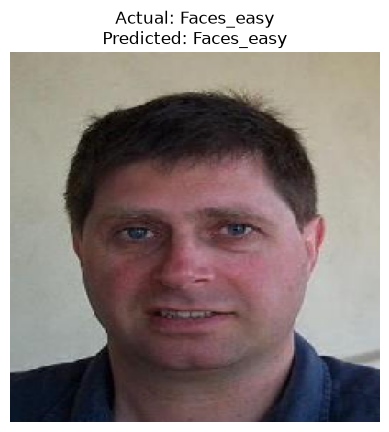

Epoch 1/2
15/15 ━━━━━━━━━━━━━━━━━━━━ 29s 2s/step - accuracy: 0.9917 - loss: 0.0325 - val_accuracy: 1.0000 - val_loss: 0.0188
Epoch 2/2
15/15 ━━━━━━━━━━━━━━━━━━━━ 24s 2s/step - accuracy: 0.9833 - loss: 0.0703 - val_accuracy: 1.0000 - val_loss: 0.0103
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step - accuracy: 1.0000 - loss: 0.0103

Fine Tuned Test Loss: 0.010280133225023746
Fine Tuned Test Accuracy: 1.0


In [9]:
import os
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras.applications import VGG16
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense, Dropout
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. DATASET PATH
# ------------------------------------------------------------

dataset_path = r"D:\Downloads\LP IV Updated Datasets\LP IV Updated Datasets\Object Detection\caltech-101"
WEIGHTS_PATH = r"D:\Downloads\LP IV Updated Datasets\LP IV Updated Datasets\Object Detection\vgg16_weights_tf_dim_ordering_tf_kernels_notop.h5"

# ------------------------------------------------------------
# 2. SELECT ONLY 5 CLASSES AND 30 IMAGES PER CLASS
# ------------------------------------------------------------

classes = sorted(os.listdir(dataset_path))[:5]

X = []
y = []

for label, class_name in enumerate(classes):

    class_path = os.path.join(dataset_path, class_name)

    images = os.listdir(class_path)[:30]

    for image_name in images:

        image_path = os.path.join(class_path, image_name)

        try:
            img = load_img(image_path, target_size=(224, 224))
            img = img_to_array(img)

            X.append(img)
            y.append(label)

        except:
            pass

X = np.array(X)
y = np.array(y)

print("Classes:", classes)
print("Dataset Shape:", X.shape)

# ------------------------------------------------------------
# 3. NORMALIZE THE IMAGES
# ------------------------------------------------------------

X = X / 255.0

# ------------------------------------------------------------
# 4. SPLIT DATA
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# ------------------------------------------------------------
# 5. LOAD VGG16 MODEL
# ------------------------------------------------------------

base_model = VGG16(
    weights=None,
    include_top=False,
    input_shape=(224, 224, 3)
)

# Load the provided pretrained VGG16 weights
base_model.load_weights(
    WEIGHTS_PATH
)

# ------------------------------------------------------------
# 6. FREEZE VGG16 BASE LAYERS
# ------------------------------------------------------------

base_model.trainable = False

# ------------------------------------------------------------
# 7. ADD CUSTOM CLASSIFICATION LAYERS
# ------------------------------------------------------------

model = Sequential([
    base_model,
    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.5),
    Dense(len(classes), activation="softmax")
])

# ------------------------------------------------------------
# 8. COMPILE MODEL
# ------------------------------------------------------------

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# ------------------------------------------------------------
# 9. TRAIN MODEL
# ------------------------------------------------------------

model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=8,
    validation_data=(X_test, y_test)
)

# ------------------------------------------------------------
# 10. COMPUTE LOSS AND EVALUATE
# ------------------------------------------------------------

loss, accuracy = model.evaluate(X_test, y_test)

print("\nTest Loss:", loss)
print("Test Accuracy:", accuracy)

# ------------------------------------------------------------
# 11. VISUALIZE PREDICTION
# ------------------------------------------------------------

index = 0

prediction = model.predict(X_test[index:index+1])

predicted_class = np.argmax(prediction)

plt.imshow(X_test[index])
plt.title("Actual: " + classes[y_test[index]] +
          "\nPredicted: " + classes[predicted_class])
plt.axis("off")
plt.show()

# ------------------------------------------------------------
# 12. FINE TUNING
# ------------------------------------------------------------

# Unfreeze VGG16
base_model.trainable = True

# Freeze all layers except the last 4 layers
for layer in base_model.layers[:-4]:
    layer.trainable = False

# Compile again with a small learning rate
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Train again
model.fit(
    X_train,
    y_train,
    epochs=2,
    batch_size=8,
    validation_data=(X_test, y_test)
)

loss, accuracy = model.evaluate(X_test, y_test)

print("\nFine Tuned Test Loss:", loss)
print("Fine Tuned Test Accuracy:", accuracy)